In [17]:
import json
import pandas as pd

with open ('liked_posts.json','r') as f:
    data= json.load(f)

data[0]

{'timestamp': 1788269885,
 'media': [],
 'label_values': [{'label': 'URL',
   'value': 'https://www.instagram.com/p/DcvxGaON2V8/',
   'href': 'https://www.instagram.com/p/DcvxGaON2V8/'},
  {'label': 'Caption',
   'value': 'Putting our stamp on the leagueâ\x9d\x97ï¸\x8f'},
  {'label': 'Title', 'value': ''},
  {'dict': [], 'title': 'Hashtags'},
  {'dict': [{'dict': [{'label': 'URL',
       'value': 'https://linktr.ee/OhioStateFootball'},
      {'label': 'Name', 'value': 'Ohio State Football'},
      {'label': 'Username', 'value': 'ohiostatefb'}],
     'title': ''}],
   'title': 'Owner'},
  {'dict': [], 'title': 'Brand partner'}],
 'fbid': '18098701265527135'}

In [18]:
row = {}
row['timestamp'] = data[0]['timestamp']

row

{'timestamp': 1788269885}

In [19]:
for item in data [0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']

row

{'timestamp': 1788269885,
 'URL': 'https://www.instagram.com/p/DcvxGaON2V8/',
 'Caption': 'Putting our stamp on the leagueâ\x9d\x97ï¸\x8f',
 'Title': ''}

In [20]:
for item in data [0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
    elif item.get('title') == 'Owner':
        owner_fields = item['dict'][0]['dict']
        for owner_item in owner_fields:
            row['Owner' + owner_item['label']] = owner_item['value']
row

{'timestamp': 1788269885,
 'URL': 'https://www.instagram.com/p/DcvxGaON2V8/',
 'Caption': 'Putting our stamp on the leagueâ\x9d\x97ï¸\x8f',
 'Title': '',
 'OwnerURL': 'https://linktr.ee/OhioStateFootball',
 'OwnerName': 'Ohio State Football',
 'OwnerUsername': 'ohiostatefb'}

In [21]:
tidy_rows = []

for entry in data:
    row = {}
    row['timestamp'] = entry['timestamp']

    for item in entry['label_values']:
        if 'label' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['Owner' + owner_item['label']] = owner_item['value']
    tidy_rows.append(row)
    
tidy_rows[:4]

[{'timestamp': 1788269885,
  'URL': 'https://www.instagram.com/p/DcvxGaON2V8/',
  'Caption': 'Putting our stamp on the leagueâ\x9d\x97ï¸\x8f',
  'Title': '',
  'OwnerURL': 'https://linktr.ee/OhioStateFootball',
  'OwnerName': 'Ohio State Football',
  'OwnerUsername': 'ohiostatefb'},
 {'timestamp': 1788269575,
  'URL': 'https://www.instagram.com/reel/Dct4p4cBURR/',
  'Caption': 'â\x80\x9cHeâ\x80\x99s as good as it gets.â\x80\x9d â\x80\x94 Jim Tressel breaks down his first impressions of Jeremiah Smith with @beanie26',
  'Title': '',
  'OwnerURL': 'http://www.paramountplus.com/cbscfb',
  'OwnerName': 'CBS Sports College Football',
  'OwnerUsername': 'cbssportscfb'},
 {'timestamp': 1788269468,
  'URL': 'https://www.instagram.com/reel/DcrfxFjjpDl/',
  'Caption': 'This andâ\x80¦a cuppa tea. â\x98\x95',
  'Title': '',
  'OwnerURL': 'https://visitlinkin.bio/lego',
  'OwnerName': 'LEGO',
  'OwnerUsername': 'lego'},
 {'timestamp': 1788269202,
  'URL': 'https://www.instagram.com/reel/DcuCkR5gbvo

In [22]:
likes_df = pd.DataFrame(tidy_rows)
likes_df.head(11)

,timestamp,URL,Caption,Title,OwnerURL,OwnerName,OwnerUsername
0,1788269885,https://www.instagram.com/p/DcvxGaON2V8/,Putting our stamp on the leagueâï¸,,https://linktr.ee/OhioStateFootball,Ohio State Football,ohiostatefb
1,1788269575,https://www.instagram.com/reel/Dct4p4cBURR/,âHeâs as good as it gets.â â Jim Tress...,,http://www.paramountplus.com/cbscfb,CBS Sports College Football,cbssportscfb
2,1788269468,https://www.instagram.com/reel/DcrfxFjjpDl/,This andâ¦a cuppa tea. â,,https://visitlinkin.bio/lego,LEGO,lego
3,1788269202,https://www.instagram.com/reel/DcuCkR5gbvo/,Heavy wears the crown #imposter #boardgame #pr...,,,thekoehlerbrothers,thekoehlerbrothers
4,1788233046,https://www.instagram.com/p/Dct-0XKlqnc/,Ridiculous manð,,http://barstool.link/BarstoolViceroySubmissions,Barstool Kent State ð¥,barstoolkent
5,1788205864,https://www.instagram.com/p/DctvAK2hxFt/,Columbus Crew 2 announced today the transfer o...,,https://apple.co/Crew_MLS,Columbus Crew 2,columbuscrew2
6,1788205808,https://www.instagram.com/p/DctvDriFuPY/,ðâï¸ | VÃ¤lkommen ððððð ð...,,https://sandvikensif.ebiljett.nu/Products,Sandvikens IF,sandvikensif
7,1788196946,https://www.instagram.com/reel/Dcrs7mSNoN_/,BLOCKED BY JAMES. ð­ð (via @abhi.khanal47),,https://www.youtube.com/watch?v=J2xyoBnl6BU,House of Highlights,houseofhighlights
8,1788196700,https://www.instagram.com/reel/DY-vzqJqq4y/,Lemme hear both sides of the story \n\n#fyp #r...,,https://www.tiktok.com/@khanfessions?_r=1&_t=Z...,Khan,the.khanfessions
9,1788195742,https://www.instagram.com/reel/DcsgWEnAtbg/,#TVã¢ãã¡ãONE PIECEã ã¨ã«ããç·¨ æ...,,,,uniquefm


In [23]:
likes_df['DateTime'] = pd.to_datetime(likes_df['timestamp'], unit='s')
likes_df[['timestamp', 'DateTime']].head()

,timestamp,DateTime
0,1788269885,2026-09-01 13:38:05
1,1788269575,2026-09-01 13:32:55
2,1788269468,2026-09-01 13:31:08
3,1788269202,2026-09-01 13:26:42
4,1788233046,2026-09-01 03:24:06


In [24]:
likes_df.shape

(36747, 8)

In [25]:
likes_df['OwnerUsername'].isna().sum()

np.int64(0)

In [26]:
likes_df.dtypes

timestamp                int64
URL                        str
Caption                    str
Title                      str
OwnerURL                   str
OwnerName                  str
OwnerUsername              str
DateTime         datetime64[s]
dtype: object

In [27]:
likes_df.groupby("OwnerUsername")["DateTime"].count()

OwnerUsername
001_h_official    1
10xfunny          1
213offc           1
270315sports      1
270hoops          4
                 ..
zubz_9            1
zucctheberg       1
zuppisports       1
zwebackhd         1
zygard            1
Name: DateTime, Length: 3272, dtype: int64

In [28]:
likes_by_account = (
    likes_df.groupby("OwnerUsername")["DateTime"]
    .count()
    .sort_values(ascending=False)
)
likes_by_account.head(10)

OwnerUsername
espnfc          2764
manutd          2735
brfootball      2190
433             1730
espn            1270
columbuscrew    1211
ohiostatefb     1089
fabriziorom     1043
sportscenter     835
sportbible       745
Name: DateTime, dtype: int64

# Assignment Starts Here

Name of Data Report

Joseph Eberts

9/20/26

The source of the data is from meta/instagram. The data was created by me because the data is from my personal instagram account.

This data was created because of the actions and decisions I made on my instagram account. This data gives personal information about things such as who i follow and who is following me on the platform.

This data is reliable because it only shows data directly from the account based on posts liked, people followed, and other interactions the user made on the account.

This data may be unreliable because certain things you look for may not have a specific name in a column, but might be under the same topic.

**Hypothesis:** I hypothesize that I follow more Instagram accounts than the number of accounts that follow me.


**Theoretical:** The hypothesis is based on the idea that I follow more Instagram accounts than the number of accounts that follow me.

**Statistical:** I will find the number of accounts in my followers and following data and compare the two totals to determine whether I follow more accounts than follow me.

I would choose the **following.json** and **followers.json** files because they contain the Instagram accounts that I follow and who follow me. I can use these files to count how many accounts I follow and compare that number to the number of accounts in my followers data.


In [53]:
import json
import pandas as pd

In [54]:
with open('following.json', 'r') as f:
    data = json.load(f)

In [37]:
with open('followers.json', 'r') as f:
    followers = json.load(f)

In [38]:
type(data)

dict

In [52]:
following_df = pd.DataFrame(data['relationships_following'])

In [47]:
followers_df = pd.DataFrame({
    'username': [item['string_list_data'][0]['value'] for item in followers]
})

In [55]:
following_df = following_df[['title']]
following_df = following_df.rename(columns={'title': 'username'})

In [56]:
following_df.head(10)

,username
0,gray_son_geese
1,kentstateonline
2,nolanliang_
3,londennsears
4,mattyfc__
5,carlos_baleba
6,kentstateultimate
7,noahanderson14
8,letourdefrance
9,tadejpogacar


In [57]:
followers_df.head(10)

,username
0,gray_son_geese
1,nolanliang_
2,maybeafrenchteacher
3,malaki_stan03
4,abby_rawlings74
5,maggiemm_10
6,heidibartolone
7,elliotfixari.15
8,abby.hartke
9,cconnroo


In [58]:
print("Following:", len(following_df))
print("Followers:", len(followers_df))

Following: 746
Followers: 445


In [59]:
difference = len(following_df) - len(followers_df)
print(difference)

301


Used ChatGPT to understand how to calculate and print the difference between my followers and following.

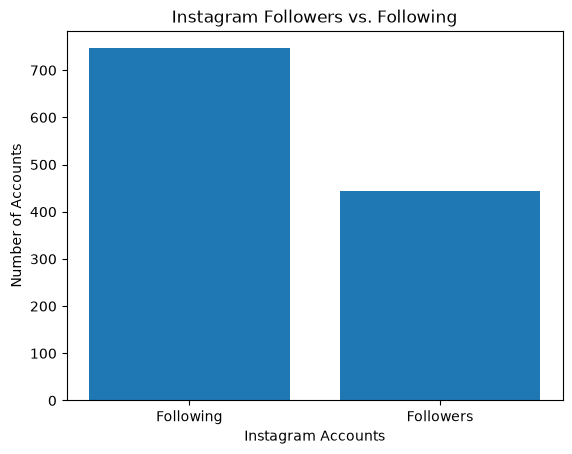

In [60]:
import matplotlib.pyplot as plt

counts = {
    'Following': len(following_df),
    'Followers': len(followers_df)
}

plt.bar(counts.keys(), counts.values())
plt.xlabel('Instagram Accounts')
plt.ylabel('Number of Accounts')
plt.title('Instagram Followers vs. Following')
plt.show()

Used ChatGpt to fix this section of code:

counts = {
    'Following': len(following_df),
    'Followers': len(followers_df)
}

In [69]:
not_following_back = following_df[
    ~following_df['username'].isin(followers_df['username'])
]

In [70]:
not_following_back

,username
1,kentstateonline
3,londennsears
4,mattyfc__
5,carlos_baleba
6,kentstateultimate
...,...
712,drew.leskowyak
713,colincarr.4
719,joshhay88
723,thebraydencooper


In [71]:
len(not_following_back)

463

The number of accounts that are not following me back

In [74]:
following_back = following_df[
    following_df['username'].isin(followers_df['username'])
]

len(following_back)

283

The number of accounts that I follow that also follow me

<Axes: >

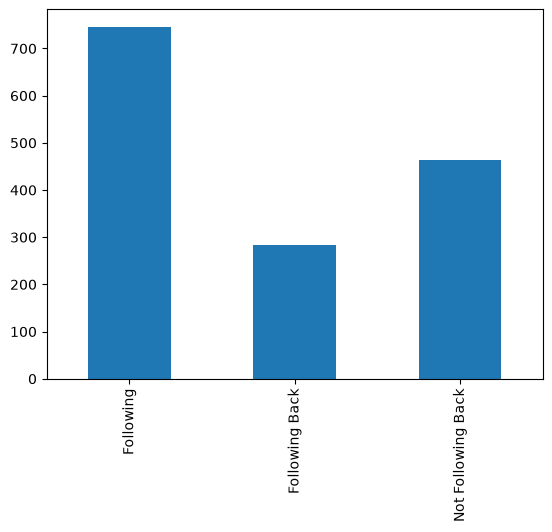

In [76]:
counts = {
    'Following': len(following_df),
    'Following Back': len(following_back),
    'Not Following Back': len(not_following_back)
}

pd.Series(counts).plot(kind='bar')

I used ChatGPT to help create this graph comparing the accounts I follow, the accounts that follow me back, and the accounts that do not follow me back. The graph shows that I follow 746 accounts, 283 follow me back, and 463 do not follow me back.


The DataFrame shows the Instagram accounts I follow and the accounts that follow me. Each row represents an account, so the data follows tidy principles. The data can be used to test my hypothesis by comparing the number of followers and accounts I follow. The different structures of the two JSON files were a little confusing at first but I was able to tell the differences.